In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 6)

# File dữ liệu nằm cùng thư mục với notebook này
file_path = "US_Accidents_March23.csv"

# Kết quả
thu_muc_luu = "."

In [ ]:
# 1. Đọc toàn bộ bộ dữ liệu
print("1. Đang đọc toàn bộ dữ liệu gốc...")
df = pd.read_csv(file_path)

# 2. Lập bảng thống kê số lượng và tỷ lệ % data thiếu của từng cột
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_table = pd.DataFrame({
    'Số lượng trống (NaN)': missing_count,
    'Tỷ lệ trống (%)': missing_percent.round(2)
})

# Chỉ in ra các cột có dữ liệu bị trống, sắp xếp từ cao xuống thấp
missing_table = missing_table[missing_table['Số lượng trống (NaN)'] > 0]
missing_table = missing_table.sort_values(by='Tỷ lệ trống (%)', ascending=False)

print("\nBẢNG THỐNG KÊ CÁC CỘT BỊ THIẾU DỮ LIỆU")
print(missing_table)

# Kiểm tra dòng trùng lặp: cùng thời điểm bắt đầu và cùng tọa độ thì gần như chắc chắn là cùng một vụ
so_dong_trung = df.duplicated(subset=['Start_Time', 'Start_Lat', 'Start_Lng']).sum()
print("\nSố dòng trùng lặp (cùng Start_Time, Start_Lat, Start_Lng):", so_dong_trung)
# df = df.drop_duplicates(subset=['Start_Time', 'Start_Lat', 'Start_Lng'])   # bỏ dấu # đầu dòng nếu muốn xóa các dòng trùng

1. Đang đọc toàn bộ dữ liệu gốc...
Kích thước dữ liệu gốc: 7,728,394 dòng và 46 cột

=== BẢNG THỐNG KÊ CÁC CỘT BỊ KHUYẾT THIẾU DỮ LIỆU ===
                       Số lượng trống (NaN)  Tỷ lệ trống (%)
End_Lat                             3402762            44.03
End_Lng                             3402762            44.03
Precipitation(in)                   2203586            28.51
Wind_Chill(F)                       1999019            25.87
Wind_Speed(mph)                      571233             7.39
Visibility(mi)                       177098             2.29
Wind_Direction                       175206             2.27
Humidity(%)                          174144             2.25
Weather_Condition                    173459             2.24
Temperature(F)                       163853             2.12
Pressure(in)                         140679             1.82
Weather_Timestamp                    120228             1.56
Sunrise_Sunset                        23246             0.30
Civil_T

In [4]:
# Kiểm tra dòng trùng lặp: cùng thời điểm bắt đầu và cùng tọa độ thì gần như chắc chắn là cùng một vụ
so_dong_trung = df.duplicated(subset=['Start_Time', 'Start_Lat', 'Start_Lng']).sum()
print("\nSố dòng trùng lặp (cùng Start_Time, Start_Lat, Start_Lng):", so_dong_trung)
# df = df.drop_duplicates(subset=['Start_Time', 'Start_Lat', 'Start_Lng'])   # bỏ dấu # đầu dòng nếu muốn xóa các dòng trùng


Số dòng trùng lặp (cùng Start_Time, Start_Lat, Start_Lng): 399321


In [ ]:
print("\n2. Đang xử lý dữ liệu thiếu theo 4 phương pháp...")

# --- PHƯƠNG PHÁP 1: XÓA CỘT (DROP COLUMNS) ---
# Kiểm tra trước khi xóa
print("Tương quan Wind_Chill(F) với Temperature(F):", round(df['Wind_Chill(F)'].corr(df['Temperature(F)']), 3))   # gần 1 nghĩa là hai cột gần như trùng thông tin
for c in ['Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']:
    print(c, "giống Sunrise_Sunset ở", round((df[c] == df['Sunrise_Sunset']).mean() * 100, 1), "% số dòng")   # càng gần 100% càng trùng thông tin

# a) Cột bị xóa vì thiếu quá nhiều:
# - End_Lat, End_Lng: thiếu 44,03%. Vị trí tai nạn đã có ở Start_Lat, Start_Lng.
# - Wind_Chill(F): thiếu 25,87%. Số tương quan với Temperature(F) in ở trên để đối chiếu khi viết báo cáo.
cols_high_missing = ['End_Lat', 'End_Lng', 'Wind_Chill(F)']

# b) Cột không dùng cho phân tích:
# - ID, Source: mã định danh và nguồn dữ liệu, không mô tả đặc điểm của vụ tai nạn.
# - Street, Zipcode, Airport_Code: quá chi tiết , khó dùng để thống kê.
# - Country: chỉ có 1 giá trị 'US'.
# - Weather_Timestamp: thời điểm đo thời tiết (chỉ thiếu 1,56%), không dùng trong phân tích; thời gian vụ tai nạn đã có ở Start_Time.
# - 3 cột ngày/đêm phụ (Civil_Twilight, Nautical_Twilight, Astronomical_Twilight), giữ Sunrise_Sunset đại diện.
cols_redundant = [
    'ID', 'Source', 'Description', 'Street', 'Zipcode', 'Country', 'Airport_Code', 'Weather_Timestamp',
    'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight'
]
df = df.drop(columns=cols_high_missing + cols_redundant)
print(f"- Đã loại bỏ {len(cols_high_missing) + len(cols_redundant)} cột khuyết thiếu nặng/dư thừa. Còn lại {df.shape[1]} cột.")

# --- PHƯƠNG PHÁP 2: ĐIỀN THEO NGHIỆP VỤ THỰC TẾ (DOMAIN IMPUTATION) ---
# Cột Lượng mưa (Precipitation): giả định ô trống nghĩa là không mưa -> điền 0
# Kiểm tra giả định: các dòng bị trống lượng mưa thường có thời tiết gì? , nếu 'Rain' chiếm tỷ lệ cao thì giả định yếu.
print(df[df['Precipitation(in)'].isnull()]['Weather_Condition'].value_counts(normalize=True).head(5).round(3))
df['Precipitation(in)'] = df['Precipitation(in)'].fillna(0)

# --- PHƯƠNG PHÁP 3: ĐIỀN MEDIAN THEO TỪNG BANG (GROUP-BASED MEDIAN IMPUTATION) ---
# Khí hậu mỗi Bang rất khác nhau, nên điền ô trống của Bang nào bằng Median của chính Bang đó
weather_num_cols = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)']

for col in weather_num_cols:
    # Điền bằng median của từng Bang
    df[col] = df[col].fillna(df.groupby('State')[col].transform('median'))
    # Nếu có dòng nào vẫn trống thì điền bằng median toàn cục
    df[col] = df[col].fillna(df[col].median())

# Cột Hướng gió (Wind_Direction - dạng chữ): Điền bằng giá trị xuất hiện nhiều nhất
most_common_wind = df['Wind_Direction'].mode()[0]
df['Wind_Direction'] = df['Wind_Direction'].fillna(most_common_wind)

# --- PHƯƠNG PHÁP 4: XÓA DÒNG (DROP ROWS) VỚI CÁC CỘT THIẾU RẤT ÍT (< 2%) ---
# Các cột City, Timezone, Weather_Condition, Sunrise_Sunset chỉ thiếu một tỷ lệ rất nhỏ -> Xóa dòng
df = df.dropna(subset=['City', 'Timezone', 'Weather_Condition', 'Sunrise_Sunset'])

print("- Tổng số ô bị trống trong toàn bộ bảng SAU khi xử lý:", df.isnull().sum().sum())


2. Đang xử lý dữ liệu thiếu theo 4 phương pháp...


KeyError: 'Wind_Chill(F)'

In [ ]:
print("\n3. Đang xử lý thời gian và lọc bỏ Outliers...")

# 1. Chuyển đổi kiểu thời gian và tính Thời lượng tai nạn (Duration - phút).
df['Start_Time'] = pd.to_datetime(df['Start_Time'], format='mixed')
df['End_Time'] = pd.to_datetime(df['End_Time'], format='mixed')

df['Duration(min)'] = (df['End_Time'] - df['Start_Time']).dt.total_seconds() / 60
df['Year'] = df['Start_Time'].dt.year
df['Month'] = df['Start_Time'].dt.month
df['Hour'] = df['Start_Time'].dt.hour
df['DayOfWeek'] = df['Start_Time'].dt.dayofweek  # 0 = Thứ Hai, ..., 6 = Chủ Nhật

# 2. Xử lý Outliers.
rows_before = len(df)

# Tính ngưỡng phân vị 99.5% cho khoảng cách (Distance) để cắt bỏ 0.5% các giá trị cực đoan nhất
dist_upper_limit = df['Distance(mi)'].quantile(0.995)

# Áp dụng bộ lọc loại bỏ các giá trị vô lý (lỗi cảm biến / lỗi nhập liệu):
# - Duration(min): Phải > 0 phút (tránh lỗi End_Time < Start_Time) và <= 1440 phút (24 giờ)
# - Temperature(F): Từ -40 độ F đến 130 độ F
# - Humidity(%): Từ 0% đến 100%
# - Visibility(mi): Từ 0 đến 50 dặm
# - Wind_Speed(mph): Từ 0 đến 150 mph (tránh các dòng lỗi cảm biến ghi gió > 800 mph)
# - Pressure(in): Áp suất khí quyển hợp lý từ 25 đến 35 inches Hg
df = df[
    (df['Duration(min)'] > 0) & (df['Duration(min)'] <= 1440) &
    (df['Temperature(F)'] >= -40) & (df['Temperature(F)'] <= 130) &
    (df['Humidity(%)'] >= 0) & (df['Humidity(%)'] <= 100) &
    (df['Visibility(mi)'] >= 0) & (df['Visibility(mi)'] <= 50) &
    (df['Wind_Speed(mph)'] >= 0) & (df['Wind_Speed(mph)'] <= 150) &
    (df['Pressure(in)'] >= 25) & (df['Pressure(in)'] <= 35) &
    (df['Distance(mi)'] >= 0) & (df['Distance(mi)'] <= dist_upper_limit)
]
df = df.copy()   # tạo bản sao riêng để tránh cảnh báo khi thêm cột bên dưới

print(f"- Đã lọc bỏ {rows_before - len(df):,} dòng ngoại lai. Số dòng sạch còn lại: {len(df):,}")


3. Đang xử lý thời gian và lọc bỏ Outliers...
- Đã lọc bỏ 163,475 dòng ngoại lai. Số dòng sạch còn lại: 7,371,138


In [ ]:
print("\n4. Đang chuẩn hóa và mã hóa biến...")

# 1. Mã hóa toàn bộ 13 cột Hạ tầng giao thông từ kiểu True/False sang số nguyên 1/0
bool_columns = [
    'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction',
    'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop',
    'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop'
]
for col in bool_columns:
    df[col] = df[col].astype(int)

# 2. Mã hóa cột Ngày/Đêm (Sunrise_Sunset) sang biến nhị phân (Day = 1, Night = 0)
df['Is_Daylight'] = df['Sunrise_Sunset'].map({'Day': 1, 'Night': 0})

# 3. Chuẩn hóa biến Weather_Condition (gom hơn 100 nhãn thời tiết chi tiết về 6 nhóm chuẩn)
def group_weather(text):
    text = str(text).lower()
    if 'clear' in text or 'fair' in text:
        return 'Clear'
    elif 'rain' in text or 'storm' in text or 'thunder' in text or 'drizzle' in text:
        return 'Rain'
    elif 'snow' in text or 'ice' in text or 'sleet' in text or 'wintry' in text:
        return 'Snow'
    elif 'fog' in text or 'mist' in text or 'haze' in text or 'smoke' in text:
        return 'Fog'
    elif 'cloud' in text or 'overcast' in text:
        return 'Cloudy'
    else:
        return 'Other'

df['Weather_Group'] = df['Weather_Condition'].apply(group_weather)

# Kiểm tra: những loại thời tiết nào đang bị xếp vào nhóm 'Other'?
print(df[df['Weather_Group'] == 'Other']['Weather_Condition'].value_counts().head(10))

# 4. Chuẩn hóa cột Wind_Direction (gom 24 hướng gió về 6 nhóm chính)
def group_wind(direction):
    d = str(direction).upper()
    if d in ['CALM']:
        return 'Calm'
    elif d in ['N', 'NORTH', 'NNE', 'NNW', 'NE', 'NW']:
        return 'North'
    elif d in ['S', 'SOUTH', 'SSE', 'SSW', 'SE', 'SW']:
        return 'South'
    elif d in ['E', 'EAST', 'ENE', 'ESE']:
        return 'East'
    elif d in ['W', 'WEST', 'WNW', 'WSW']:
        return 'West'
    else:
        return 'Variable'

df['Wind_Group'] = df['Wind_Direction'].apply(group_wind)


4. Đang chuẩn hóa và mã hóa biến...
Weather_Condition
N/A Precipitation          2851
Showers in the Vicinity    1274
Blowing Dust / Windy        243
Blowing Dust                185
Widespread Dust             179
Small Hail                   75
Sand / Dust Whirlwinds       50
Hail                         39
Squalls / Windy              39
Squalls                      33
Name: count, dtype: int64


In [22]:
# 1. Xuất dữ liệu sạch ra file parquet 
print("\n5. Đang xuất dữ liệu sạch...")
df.to_parquet(os.path.join(thu_muc_luu, "US_Accidents_Cleaned.parquet"), index=False, engine='fastparquet')
print("Đã xuất xong US_Accidents_Cleaned.parquet!")

# 2. Thống kê mô tả các biến định lượng
numeric_cols = [
    'Severity', 'Distance(mi)', 'Duration(min)', 'Temperature(F)',
    'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)'
]
print("\n BẢNG THỐNG KÊ MÔ TẢ CÁC BIẾN ĐỊNH LƯỢNG ")
print(df[numeric_cols].describe().round(2))


5. Đang xuất dữ liệu sạch...
Đã xuất xong US_Accidents_Cleaned.parquet!

 BẢNG THỐNG KÊ MÔ TẢ CÁC BIẾN ĐỊNH LƯỢNG 
         Severity  Distance(mi)  Duration(min)  Temperature(F)  Humidity(%)  \
count  7371138.00    7371138.00     7371138.00      7371138.00   7371138.00   
mean         2.21          0.47         107.61           61.93        64.95   
std          0.48          1.06         123.55           18.81        22.66   
min          1.00          0.00           1.22          -40.00         1.00   
25%          2.00          0.00          30.82           50.00        49.00   
50%          2.00          0.02          74.62           64.00        67.00   
75%          2.00          0.43         124.12           76.00        84.00   
max          4.00          9.51        1440.00          129.20       100.00   

       Pressure(in)  Visibility(mi)  Wind_Speed(mph)  Precipitation(in)  
count    7371138.00      7371138.00       7371138.00         7371138.00  
mean          29.61     

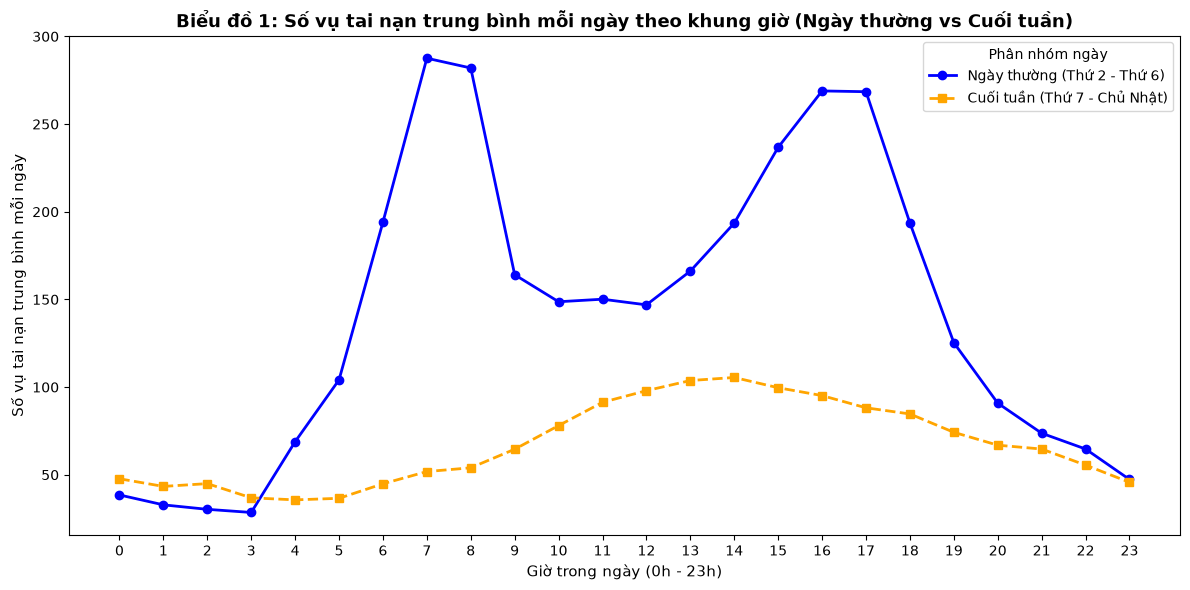

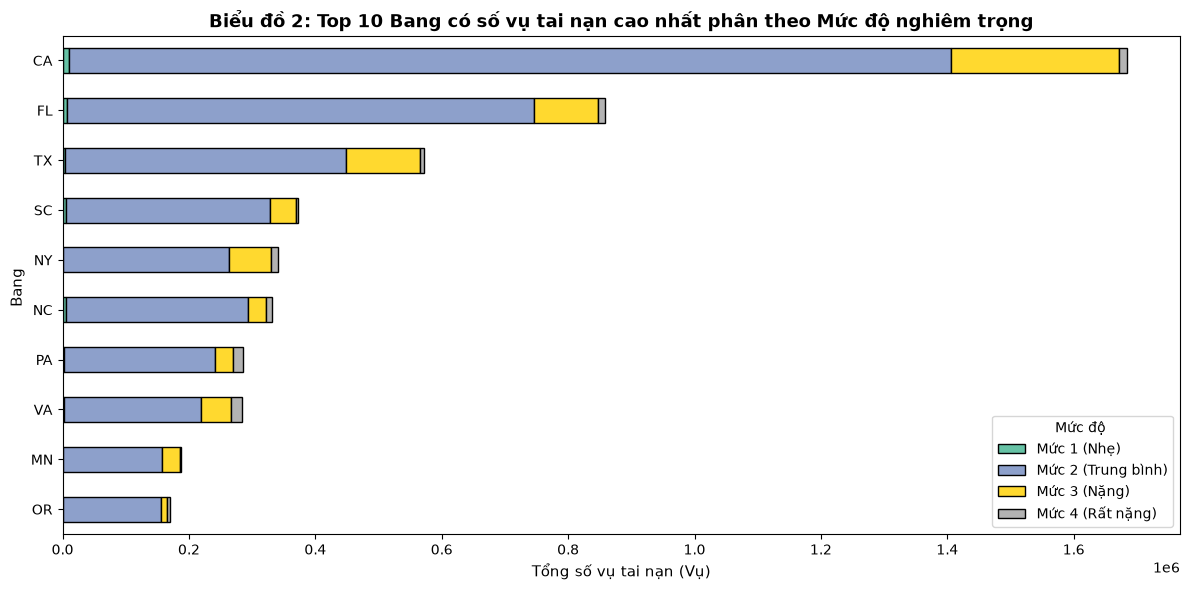

In [18]:
# 3. BIỂU ĐỒ 1: LINE CHART - Xu hướng tai nạn theo Giờ (Ngày thường vs Cuối tuần)
df_weekday = df[df['DayOfWeek'] < 5]
df_weekend = df[df['DayOfWeek'] >= 5]

# Trung bình mỗi ngày = tổng số vụ của từng giờ / số ngày
weekday_hourly = df_weekday.groupby('Hour').size() / df_weekday['Start_Time'].dt.date.nunique()
weekend_hourly = df_weekend.groupby('Hour').size() / df_weekend['Start_Time'].dt.date.nunique()

plt.figure(figsize=(12, 6))
plt.plot(weekday_hourly.index, weekday_hourly.values, marker='o', linewidth=2, color='blue', label='Ngày thường (Thứ 2 - Thứ 6)')
plt.plot(weekend_hourly.index, weekend_hourly.values, marker='s', linewidth=2, color='orange', linestyle='--', label='Cuối tuần (Thứ 7 - Chủ Nhật)')
plt.title('Biểu đồ 1: Số vụ tai nạn trung bình mỗi ngày theo khung giờ (Ngày thường vs Cuối tuần)', fontsize=13, fontweight='bold')
plt.xlabel('Giờ trong ngày (0h - 23h)', fontsize=11)
plt.ylabel('Số vụ tai nạn trung bình mỗi ngày', fontsize=11)
plt.xticks(range(0, 24))
plt.legend(title='Phân nhóm ngày')
plt.tight_layout()
plt.savefig(os.path.join(thu_muc_luu, 'Chart1_LineChart.png'), dpi=300)
plt.show()

# 4. BIỂU ĐỒ 2: STACKED BAR CHART - Top 10 Bang có nhiều tai nạn nhất theo Mức độ nghiêm trọng
top10_states = df['State'].value_counts().head(10).index
df_top10 = df[df['State'].isin(top10_states)]

state_severity_table = pd.crosstab(df_top10['State'], df_top10['Severity'])
state_severity_table['Total'] = state_severity_table.sum(axis=1)
state_severity_table = state_severity_table.sort_values(by='Total', ascending=True).drop(columns='Total')

state_severity_table.plot(kind='barh', stacked=True, figsize=(12, 6), colormap='Set2', edgecolor='black')
plt.title('Biểu đồ 2: Top 10 Bang có số vụ tai nạn cao nhất phân theo Mức độ nghiêm trọng', fontsize=13, fontweight='bold')
plt.xlabel('Tổng số vụ tai nạn (Vụ)', fontsize=11)
plt.ylabel('Bang ', fontsize=11)
plt.legend(title='Mức độ ', labels=['Mức 1 (Nhẹ)', 'Mức 2 (Trung bình)', 'Mức 3 (Nặng)', 'Mức 4 (Rất nặng)'], loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(thu_muc_luu, 'Chart2_BarChart.png'), dpi=300)
plt.show()